# Step 4: Join, lag, feature sets and chronological split

Inputs: `data/features.csv` (step 2) and `data/sentiment_daily.csv` (step 3).
Outputs: `data/fused.csv`, `data/train.csv`, `data/val.csv`, `data/test.csv`.
Run the cells one by one and check the output after each.

## 4.1 Load both tables

In [10]:
%pip install scikit-learn

   ━━━━━━━━━━━━━╸━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/9.2 MB 1.1 MB/s eta 0:00:060m
Resuming download scikit_learn-1.9.1-cp314-cp314-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl (3.1 MB/9.2 MB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.2/9.2 MB 1.6 MB/s  0:00:03 eta 0:00:010m
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.3/35.3 MB 2.2 MB/s  0:00:15m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6/6 [scikit-learn] [scikit-learn]
Note: you may need to restart the kernel to use updated packages.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

features = pd.read_csv("data/features.csv", parse_dates=["Date"]).sort_values("Date").reset_index(drop=True)
sentiment = pd.read_csv("data/sentiment_daily.csv", parse_dates=["Date"]).sort_values("Date").reset_index(drop=True)

TECH_COLS = ["ret_1d", "ret_5d", "rsi_14", "macd", "macd_signal", "macd_hist", "vol_chg"]
SENT_COLS = ["sent_pos", "sent_neg", "sent_neu"]

print("features :", features.shape, features["Date"].min().date(), "to", features["Date"].max().date())
print("sentiment:", sentiment.shape, sentiment["Date"].min().date(), "to", sentiment["Date"].max().date())

features : (1979, 11) 2008-08-21 to 2016-06-30
sentiment: (1989, 5) 2008-08-08 to 2016-07-01


## 4.2 How well do the dates overlap?

Prices exist only for trading days, and news may skip some days. Only dates in both tables can be used.

In [2]:
f_dates, s_dates = set(features["Date"]), set(sentiment["Date"])
print("trading days with no news :", len(f_dates - s_dates))
print("news days that are not trading days:", len(s_dates - f_dates), "(weekends and holidays, these are dropped)")
print("days in both               :", len(f_dates & s_dates))

trading days with no news : 0
news days that are not trading days: 10 (weekends and holidays, these are dropped)
days in both               : 1979


## 4.3 Join on date

An inner join keeps only dates present in both tables.

In [3]:
data = features.merge(sentiment[["Date"] + SENT_COLS], on="Date", how="inner").sort_values("Date").reset_index(drop=True)
print(data.shape)
data[["Date", "Close", "ret_1d", "rsi_14"] + SENT_COLS].head()

(1979, 14)


,Date,Close,ret_1d,rsi_14,sent_pos,sent_neg,sent_neu
0,2008-08-21,1277.719971,0.002495,34.088826,0.071833,0.433826,0.494341
1,2008-08-22,1292.199951,0.011333,39.762473,0.118733,0.361615,0.519652
2,2008-08-25,1266.839966,-0.019625,34.208509,0.074102,0.363238,0.562660
3,2008-08-26,1271.510010,0.003686,35.981839,0.118995,0.393514,0.487491
4,2008-08-27,1281.660034,0.007983,39.780971,0.088484,0.357337,0.554178


## 4.4 Lag the sentiment by one trading day

After this, each row's sentiment comes from the previous trading day's news, so nothing used as an input
is newer than the information available when the prediction is made.
The original values are kept in a copy so we can verify the shift.

In [4]:
LAG_DAYS = 1

before = data[SENT_COLS].copy()
data[SENT_COLS] = data[SENT_COLS].shift(LAG_DAYS)

# verify: row i now holds what row i-1 held before
check = data[SENT_COLS].iloc[LAG_DAYS:].values == before.iloc[:-LAG_DAYS].values
assert check.all(), "Lag check failed"
print("lag check passed: each row now uses the previous trading day's sentiment")

data[["Date"] + SENT_COLS].head(4)

lag check passed: each row now uses the previous trading day's sentiment


,Date,sent_pos,sent_neg,sent_neu
0,2008-08-21,NaN,NaN,NaN
1,2008-08-22,0.071833,0.433826,0.494341
2,2008-08-25,0.118733,0.361615,0.519652
3,2008-08-26,0.074102,0.363238,0.562660


## 4.5 Drop incomplete rows and run checks

The first row has no previous day's sentiment, so it is dropped.

In [5]:
n_before = len(data)
data = data.dropna(subset=TECH_COLS + SENT_COLS + ["target"]).reset_index(drop=True)
data["target"] = data["target"].astype(int)

print(f"rows: {n_before} -> {len(data)}")
print("date range:", data["Date"].min().date(), "to", data["Date"].max().date())
print("missing values:", int(data[TECH_COLS + SENT_COLS + ["target"]].isna().sum().sum()))
print("duplicate dates:", int(data["Date"].duplicated().sum()))
print("dates strictly increasing:", bool(data["Date"].is_monotonic_increasing))
print("share of Up days:", round(data["target"].mean(), 3))

rows: 1979 -> 1978
date range: 2008-08-22 to 2016-06-30
missing values: 0
duplicate dates: 0
dates strictly increasing: True
share of Up days: 0.543


## 4.6 The three feature sets

These are the column lists the models will use in step 5. The data is the same, only the columns differ.

In [6]:
FEATURE_SETS = {
    "numerical-only": TECH_COLS,
    "sentiment-only": SENT_COLS,
    "multimodal": TECH_COLS + SENT_COLS,
}
for name, cols in FEATURE_SETS.items():
    print(f"{name:15s} {len(cols):2d} columns: {cols}")

numerical-only   7 columns: ['ret_1d', 'ret_5d', 'rsi_14', 'macd', 'macd_signal', 'macd_hist', 'vol_chg']
sentiment-only   3 columns: ['sent_pos', 'sent_neg', 'sent_neu']
multimodal      10 columns: ['ret_1d', 'ret_5d', 'rsi_14', 'macd', 'macd_signal', 'macd_hist', 'vol_chg', 'sent_pos', 'sent_neg', 'sent_neu']


## 4.7 Chronological split

First 70 percent of the days for training, the next 15 percent for validation, the last 15 percent for testing.
No shuffling. The split is by row position in date order, so no later day is ever in an earlier set.

In [7]:
TRAIN_FRAC, VAL_FRAC = 0.70, 0.15

n = len(data)
i_train, i_val = int(n * TRAIN_FRAC), int(n * (TRAIN_FRAC + VAL_FRAC))
train, val, test = data.iloc[:i_train].copy(), data.iloc[i_train:i_val].copy(), data.iloc[i_val:].copy()

for name, part in [("train", train), ("validation", val), ("test", test)]:
    print(f"{name:10s} {len(part):5d} rows  {part['Date'].min().date()} to {part['Date'].max().date()}  Up share {part['target'].mean():.3f}")

assert train["Date"].max() < val["Date"].min() < val["Date"].max() < test["Date"].min()
print("\nOK: train < validation < test in time, no overlap")

train       1384 rows  2008-08-22 to 2014-02-21  Up share 0.551
validation   297 rows  2014-02-24 to 2015-04-28  Up share 0.549
test         297 rows  2015-04-29 to 2016-06-30  Up share 0.502

OK: train < validation < test in time, no overlap


## 4.8 Baselines to beat

A model that always predicts the most common class in the training set already gets some accuracy.
Your real models need to do better than this on the test set.

In [8]:
majority = int(train["target"].mean() >= 0.5)
baseline_acc = (test["target"] == majority).mean()
print("always predict", "Up" if majority else "Down", "-> test accuracy:", round(baseline_acc, 3))

always predict Up -> test accuracy: 0.502


## 4.9 Scaling (demonstration)

Features have very different ranges, for example RSI runs 0 to 100 while returns are around 0.01.
The scaler must learn its mean and spread from the **training** rows only, then be applied to validation and test.
This cell only demonstrates it. Step 5 does it again inside the model loop, one scaler per feature set.

In [11]:
from sklearn.preprocessing import StandardScaler

cols = FEATURE_SETS["multimodal"]
scaler = StandardScaler().fit(train[cols])
X_train = scaler.transform(train[cols])
X_test = scaler.transform(test[cols])

print("train mean (should be about 0):", np.round(X_train.mean(axis=0), 2))
print("train std  (should be about 1):", np.round(X_train.std(axis=0), 2))
print("test mean  (not exactly 0, which is expected):", np.round(X_test.mean(axis=0), 2))

train mean (should be about 0): [-0.  0. -0. -0. -0.  0. -0. -0.  0.  0.]
train std  (should be about 1): [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
test mean  (not exactly 0, which is expected): [-0.02 -0.07 -0.3  -0.1  -0.1  -0.02 -0.01  0.88  0.06 -0.48]


## 4.10 Plot the split

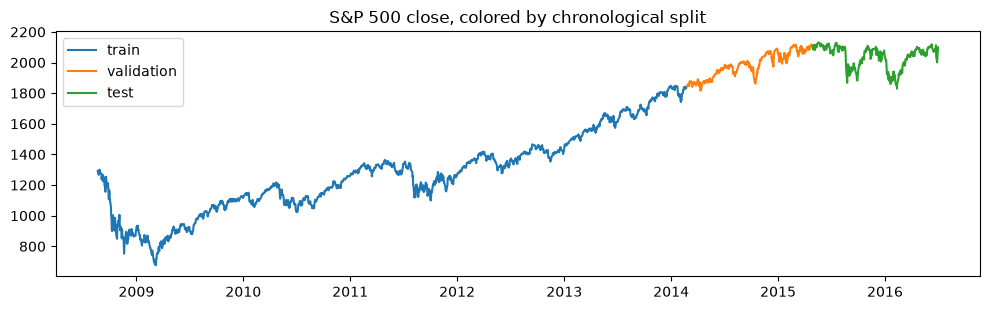

In [12]:
fig, ax = plt.subplots(figsize=(10, 3.2))
for part, label in [(train, "train"), (val, "validation"), (test, "test")]:
    ax.plot(part["Date"], part["Close"], label=label)
ax.set_title("S&P 500 close, colored by chronological split")
ax.legend()
plt.tight_layout()
plt.show()

## 4.11 Save

In [13]:
data.to_csv("data/fused.csv", index=False)
train.to_csv("data/train.csv", index=False)
val.to_csv("data/val.csv", index=False)
test.to_csv("data/test.csv", index=False)
print("saved fused.csv, train.csv, val.csv, test.csv in data/")

saved fused.csv, train.csv, val.csv, test.csv in data/


**Done with step 4 when** the lag check and the time-order check both pass, and the four CSV files exist.
Next: step 5, train Logistic Regression, Random Forest and XGBoost on the three feature sets, and evaluate them.